In [1]:
%%time

import kplex_dev

timeout_replacement = 1800
excel_path = "kplex_ML_data.xlsx"

cat_df, dfs = kplex_dev.load_excel_data(excel_path, timeout_replacement)
cat_df

CPU times: user 1.6 s, sys: 1.55 s, total: 3.15 s
Wall time: 898 ms


,dataset,n,m,d_avg,d_max,core_max,kcore_list,UMKP,AltRB,kPEX,Pivot_Br,S_Br,k_value
0,MANN-a81,3321.0,5506380.0,1658.0488,3317.0,3280.0,"[(3280,3321)]",1459.5,1800.0,1468.1,1477.4,1504.7,20
1,wikipedia_link_sr,1810.0,1637059.0,904.4525,1809.0,1798.0,"[(1795,1810),(1796,1808),(1797,1804),(1798,1803)]",22.6,18.0,737.7,740.4,738.1,20
2,scc_reality,1332.0,880733.0,661.2110,1331.0,1235.0,"[(1230,1332),(1231,1330),(1232,1309),(1233,126...",1800.0,1214.8,9.4,9.7,9.0,20
3,web-wikipedia_link_en13-all,432.0,93085.0,215.4745,431.0,427.0,"[(427,432)]",239.3,287.1,517.7,504.4,516.7,20
4,livejournal-links,442.0,94435.0,213.6538,441.0,371.0,"[(369,442),(370,409),(371,386)]",1.3,1.6,1.6,1.6,1.6,20
...,...,...,...,...,...,...,...,...,...,...,...,...,...
755,soc-flixster,264.0,11792.0,44.6667,150.0,67.0,"[(52,264),(53,262),(54,261),(55,260),(56,256),...",2.0,0.6,0.5,0.5,2.4,2
756,edit-ukwiki,281.0,14183.0,50.4733,280.0,65.0,"[(40,281),(41,279),(42,275),(43,271),(44,268),...",1.2,1.1,0.6,0.6,0.5,2
757,johnson8-4-4,70.0,1855.0,26.5000,53.0,53.0,"[(53,70)]",0.8,0.9,1.1,1.1,0.3,2
758,hamming6-2,64.0,1824.0,28.5000,57.0,57.0,"[(57,64)]",0.2,0.3,0.2,0.2,0.3,2


In [2]:
import kplex_dev

epsilon = 0.001 # need to set !!!

kplex_dev.assign_weights(cat_df, kplex_dev.W_LOG_TIME_RATIO, epsilon)
display(cat_df)
kplex_dev.export_sorted(cat_df)

,dataset,n,m,d_avg,d_max,core_max,kcore_list,UMKP,AltRB,kPEX,Pivot_Br,S_Br,k_value,weight
0,MANN-a81,3321.0,5506380.0,1658.0488,3317.0,3280.0,"[(3280,3321)]",1459.5,1800.0,1468.1,1477.4,1504.7,20,0.209693
1,wikipedia_link_sr,1810.0,1637059.0,904.4525,1809.0,1798.0,"[(1795,1810),(1796,1808),(1797,1804),(1798,1803)]",22.6,18.0,737.7,740.4,738.1,20,3.716819
2,scc_reality,1332.0,880733.0,661.2110,1331.0,1235.0,"[(1230,1332),(1231,1330),(1232,1309),(1233,126...",1800.0,1214.8,9.4,9.7,9.0,20,5.298317
3,web-wikipedia_link_en13-all,432.0,93085.0,215.4745,431.0,427.0,"[(427,432)]",239.3,287.1,517.7,504.4,516.7,20,0.771678
4,livejournal-links,442.0,94435.0,213.6538,441.0,371.0,"[(369,442),(370,409),(371,386)]",1.3,1.6,1.6,1.6,1.6,20,0.207639
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
755,soc-flixster,264.0,11792.0,44.6667,150.0,67.0,"[(52,264),(53,262),(54,261),(55,260),(56,256),...",2.0,0.6,0.5,0.5,2.4,2,1.568616
756,edit-ukwiki,281.0,14183.0,50.4733,280.0,65.0,"[(40,281),(41,279),(42,275),(43,271),(44,268),...",1.2,1.1,0.6,0.6,0.5,2,0.875469
757,johnson8-4-4,70.0,1855.0,26.5000,53.0,53.0,"[(53,70)]",0.8,0.9,1.1,1.1,0.3,2,1.299283
758,hamming6-2,64.0,1824.0,28.5000,57.0,57.0,"[(57,64)]",0.2,0.3,0.2,0.2,0.3,2,0.405465


# Y statistics

Check how many times each algorithm reaches the best, for different k values (if 2 algorithms reach tie as the fastest, each gets 0.5)

In [8]:
def count_fastest_by_k_with_ties(dfs, y_columns):
    """
    Count fastest algorithms per k-value, splitting counts for ties.
    
    Args:
        dfs: List of DataFrames (one per k-value)
        y_columns: List of algorithm columns
        
    Returns:
        dict: {k_value: {algorithm: count}} 
              where counts may be fractions due to ties
    """
    k_fastest_counts = {}
    
    for df in dfs:
        k_value = df['k_value'].iloc[0]
        k_fastest_counts[k_value] = {col: 0.0 for col in y_columns}
        
        for _, row in df.iterrows():
            min_val = row[y_columns].min()
            # Find all algorithms that achieved the minimum
            tied_algs = [col for col in y_columns if row[col] == min_val]
            # Distribute count equally among tied algorithms
            for alg in tied_algs:
                k_fastest_counts[k_value][alg] += 1/len(tied_algs)
                
    return k_fastest_counts

# Usage:
fastest_by_k = count_fastest_by_k_with_ties(dfs, kplex_dev.y_columns)

# Print results with 4 decimal places for fractional counts
for k, counts in sorted(fastest_by_k.items()):
    print(f"\nk = {k}:")
    for alg, count in counts.items():
        print(f"  {alg}: {count:.4f}")


k = 2:
  UMKP: 5.5833
  AltRB: 10.7500
  kPEX: 12.9167
  Pivot_Br: 11.1667
  S_Br: 37.5833

k = 3:
  UMKP: 8.9833
  AltRB: 8.9833
  kPEX: 27.2333
  Pivot_Br: 15.9833
  S_Br: 18.8167

k = 4:
  UMKP: 3.7333
  AltRB: 12.7333
  kPEX: 30.4000
  Pivot_Br: 11.9000
  S_Br: 20.2333

k = 5:
  UMKP: 8.4000
  AltRB: 10.9000
  kPEX: 27.1500
  Pivot_Br: 16.9000
  S_Br: 17.6500

k = 6:
  UMKP: 11.2333
  AltRB: 7.9833
  kPEX: 26.9000
  Pivot_Br: 16.7333
  S_Br: 14.1500

k = 7:
  UMKP: 2.7000
  AltRB: 10.7000
  kPEX: 26.3667
  Pivot_Br: 13.8667
  S_Br: 14.3667

k = 8:
  UMKP: 4.5000
  AltRB: 5.5000
  kPEX: 26.6667
  Pivot_Br: 14.1667
  S_Br: 15.1667

k = 9:
  UMKP: 5.7500
  AltRB: 6.7500
  kPEX: 28.9167
  Pivot_Br: 9.1667
  S_Br: 14.4167

k = 10:
  UMKP: 4.8333
  AltRB: 6.8333
  kPEX: 27.3333
  Pivot_Br: 10.8333
  S_Br: 15.1667

k = 15:
  UMKP: 7.7500
  AltRB: 8.7500
  kPEX: 23.2500
  Pivot_Br: 11.2500
  S_Br: 5.0000

k = 20:
  UMKP: 12.2000
  AltRB: 3.2000
  kPEX: 15.7000
  Pivot_Br: 5.2000
  S_Br: 8

In [12]:
import pandas as pd

# Convert the nested dictionary to a DataFrame
df_plot = pd.DataFrame.from_dict(fastest_by_k, orient='index')
df_plot.index.name = 'k'
df_plot.columns.name = 'Algorithm'
df_plot

Algorithm,UMKP,AltRB,kPEX,Pivot_Br,S_Br
k,,,,,
2,5.583333,10.750000,12.916667,11.166667,37.583333
3,8.983333,8.983333,27.233333,15.983333,18.816667
4,3.733333,12.733333,30.400000,11.900000,20.233333
5,8.400000,10.900000,27.150000,16.900000,17.650000
6,11.233333,7.983333,26.900000,16.733333,14.150000
7,2.700000,10.700000,26.366667,13.866667,14.366667
8,4.500000,5.500000,26.666667,14.166667,15.166667
9,5.750000,6.750000,28.916667,9.166667,14.416667
10,4.833333,6.833333,27.333333,10.833333,15.166667


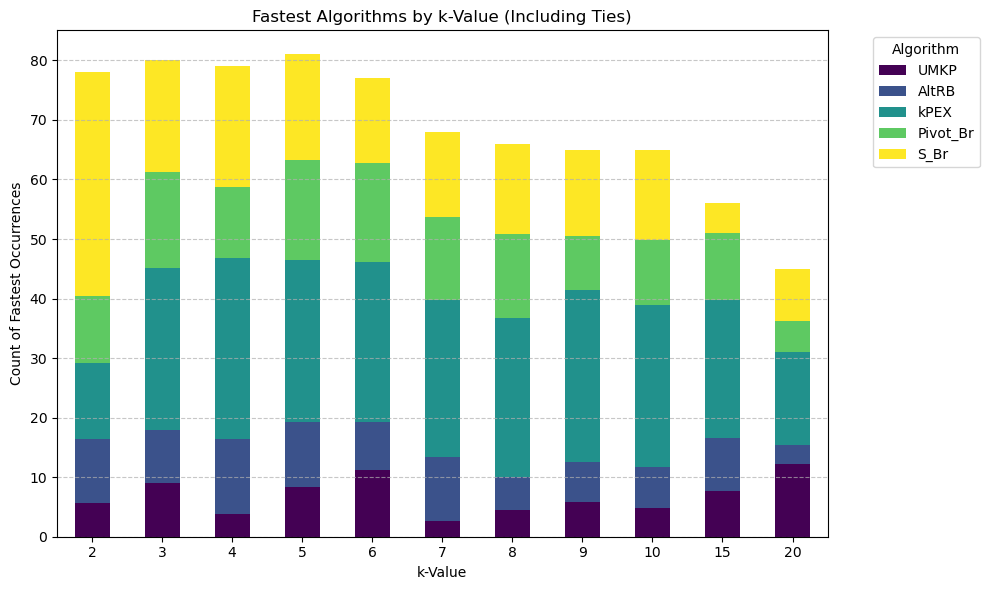

In [18]:
import matplotlib.pyplot as plt

# Plot
ax = df_plot.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')

# Customize the plot
plt.title('Fastest Algorithms by k-Value (Including Ties)')
plt.xlabel('k-Value')
plt.ylabel('Count of Fastest Occurrences')
plt.legend(title='Algorithm', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Rotate x-axis labels for readability
plt.xticks(rotation=0)

# Show the plot
plt.tight_layout()
plt.show()

Overall best frequency (among all k values)

In [10]:
def count_fastest_overall_with_ties(dfs, y_columns):
    """
    Count fastest algorithms overall (across all k-values), splitting counts for ties.
    
    Args:
        dfs: List of DataFrames (one per k-value)
        y_columns: List of algorithm columns
        
    Returns:
        dict: {algorithm: total_count} 
              where counts may be fractions due to ties
    """
    overall_counts = {col: 0.0 for col in y_columns}
    
    for df in dfs:
        for _, row in df.iterrows():
            min_val = row[y_columns].min()
            # Find all algorithms that achieved the minimum
            tied_algs = [col for col in y_columns if row[col] == min_val]
            # Distribute count equally among tied algorithms
            for alg in tied_algs:
                overall_counts[alg] += 1/len(tied_algs)
                
    return overall_counts

# Usage:
overall_fastest = count_fastest_overall_with_ties(dfs, kplex_dev.y_columns)

# Print results with 4 decimal places for fractional counts
print("\nOverall fastest counts:")
for alg, count in overall_fastest.items():
    print(f"  {alg}: {count:.4f}")


Overall fastest counts:
  UMKP: 75.6667
  AltRB: 93.0833
  kPEX: 272.8333
  Pivot_Br: 137.1667
  S_Br: 181.2500


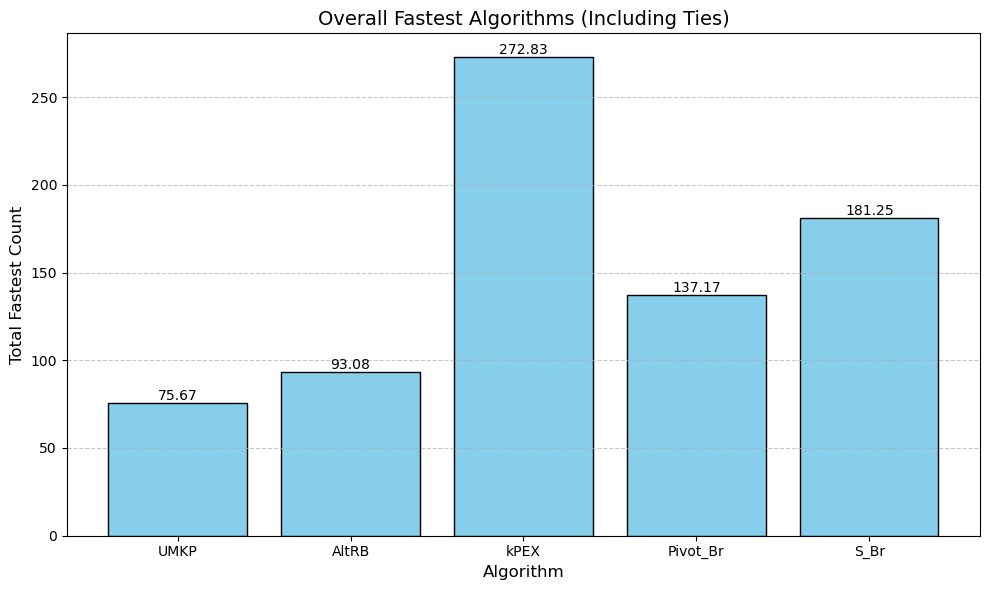

In [25]:
import pandas as pd

# Convert the dictionary to a DataFrame for plotting
df_overall = pd.DataFrame.from_dict(overall_fastest, orient='index', columns=['Count'])
df_overall.index.name = 'Algorithm'

import matplotlib.pyplot as plt

# Create the plot
plt.figure(figsize=(10, 6))
bars = plt.bar(df_overall.index, df_overall['Count'], color='skyblue', edgecolor='black')

# Add count labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, 
             f'{height:.2f}', ha='center', va='bottom')

# Customize the plot
plt.title('Overall Fastest Algorithms (Including Ties)', fontsize=14)
plt.xlabel('Algorithm', fontsize=12)
plt.ylabel('Total Fastest Count', fontsize=12)
# plt.xticks(rotation=0, ha='center')  # Rotate algorithm names for readability
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()

## Instance weight: instead of 1, use the actual min-time

In [26]:
def count_fastest_by_k_with_time_weights(dfs, y_columns):
    """
    Count fastest algorithms per k-value, splitting min-time as weights for ties.
    
    Args:
        dfs: List of DataFrames (one per k-value)
        y_columns: List of algorithm columns
        
    Returns:
        dict: {k_value: {algorithm: weighted_sum}} 
              where weights are based on the min-time (distributed among ties)
    """
    k_fastest_weights = {}
    
    for df in dfs:
        k_value = df['k_value'].iloc[0]
        k_fastest_weights[k_value] = {col: 0.0 for col in y_columns}
        
        for _, row in df.iterrows():
            min_val = row[y_columns].min()
            tied_algs = [col for col in y_columns if row[col] == min_val]
            
            # Distribute the min_val equally among tied algorithms
            for alg in tied_algs:
                k_fastest_weights[k_value][alg] += min_val / len(tied_algs)
                
    return k_fastest_weights

# Usage:
fastest_by_k_weighted = count_fastest_by_k_with_time_weights(dfs, kplex_dev.y_columns)

# Print results
for k, weights in sorted(fastest_by_k_weighted.items()):
    print(f"\nk = {k}:")
    for alg, weight in weights.items():
        print(f"  {alg}: {weight:.4f} (weighted by min-time)")


k = 2:
  UMKP: 38.7417 (weighted by min-time)
  AltRB: 793.4250 (weighted by min-time)
  kPEX: 79.6417 (weighted by min-time)
  Pivot_Br: 861.7167 (weighted by min-time)
  S_Br: 4587.1750 (weighted by min-time)

k = 3:
  UMKP: 1442.9900 (weighted by min-time)
  AltRB: 792.7900 (weighted by min-time)
  kPEX: 1947.3067 (weighted by min-time)
  Pivot_Br: 1534.3567 (weighted by min-time)
  S_Br: 2753.4567 (weighted by min-time)

k = 4:
  UMKP: 29.4400 (weighted by min-time)
  AltRB: 948.6400 (weighted by min-time)
  kPEX: 1238.3733 (weighted by min-time)
  Pivot_Br: 447.2233 (weighted by min-time)
  S_Br: 2244.3233 (weighted by min-time)

k = 5:
  UMKP: 911.5150 (weighted by min-time)
  AltRB: 836.3150 (weighted by min-time)
  kPEX: 2623.5400 (weighted by min-time)
  Pivot_Br: 1101.6650 (weighted by min-time)
  S_Br: 1829.8650 (weighted by min-time)

k = 6:
  UMKP: 454.1633 (weighted by min-time)
  AltRB: 339.0633 (weighted by min-time)
  kPEX: 4523.5967 (weighted by min-time)
  Pivot_Br:

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert to DataFrame
df_weighted = pd.DataFrame.from_dict(fastest_by_k_weighted, orient='index')
df_weighted

,UMKP,AltRB,kPEX,Pivot_Br,S_Br
2,38.741667,793.425000,79.641667,861.716667,4587.175000
3,1442.990000,792.790000,1947.306667,1534.356667,2753.456667
4,29.440000,948.640000,1238.373333,447.223333,2244.323333
5,911.515000,836.315000,2623.540000,1101.665000,1829.865000
6,454.163333,339.063333,4523.596667,375.030000,2640.646667
7,13.760000,803.760000,1656.526667,151.026667,1619.326667
8,24.200000,410.600000,1938.300000,283.600000,240.000000
9,297.275000,141.975000,1458.408333,118.533333,605.708333
10,115.350000,317.050000,4569.016667,48.716667,1292.966667
15,431.800000,1291.000000,3397.666667,70.616667,975.216667


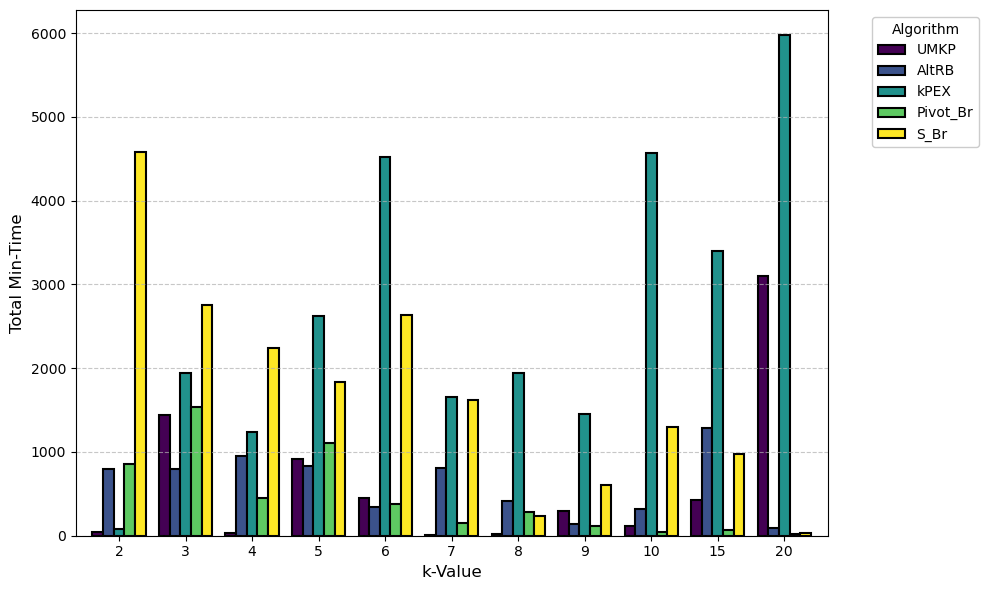

In [35]:
# Plot with thicker bars and no text labels
ax = df_weighted.plot(
    kind='bar',
    figsize=(10, 6),
    width=0.8,          # Thicker bars (default: 0.8)
    edgecolor='black',  # Black bar borders
    linewidth=1.5,      # Border thickness
    colormap='viridis'  # Color scheme
)

# Styling
plt.xlabel('k-Value', fontsize=12)
plt.ylabel('Total Min-Time', fontsize=12)
plt.legend(
    title='Algorithm',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    framealpha=1        # Opaque legend background
)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=0)  # Horizontal x-axis labels
plt.tight_layout()
plt.show()

In [36]:
def count_fastest_overall_with_time_weights(dfs, y_columns):
    """
    Count fastest algorithms overall (across all k-values), splitting min-time as weights for ties.
    
    Args:
        dfs: List of DataFrames (one per k-value)
        y_columns: List of algorithm columns
        
    Returns:
        dict: {algorithm: total_weighted_sum} 
              where weights are based on the min-time (distributed among ties)
    """
    overall_weights = {col: 0.0 for col in y_columns}
    
    for df in dfs:
        for _, row in df.iterrows():
            min_val = row[y_columns].min()
            tied_algs = [col for col in y_columns if row[col] == min_val]
            
            # Distribute the min_val equally among tied algorithms
            for alg in tied_algs:
                overall_weights[alg] += min_val / len(tied_algs)
                
    return overall_weights

# Usage:
overall_fastest_weighted = count_fastest_overall_with_time_weights(dfs, kplex_dev.y_columns)

# Print results
print("\nOverall fastest weighted by min-time:")
for alg, weight in overall_fastest_weighted.items():
    print(f"  {alg}: {weight:.4f} (weighted by min-time)")


Overall fastest weighted by min-time:
  UMKP: 6862.9750 (weighted by min-time)
  AltRB: 6772.1583 (weighted by min-time)
  kPEX: 29410.1167 (weighted by min-time)
  Pivot_Br: 5011.8750 (weighted by min-time)
  S_Br: 18823.8750 (weighted by min-time)


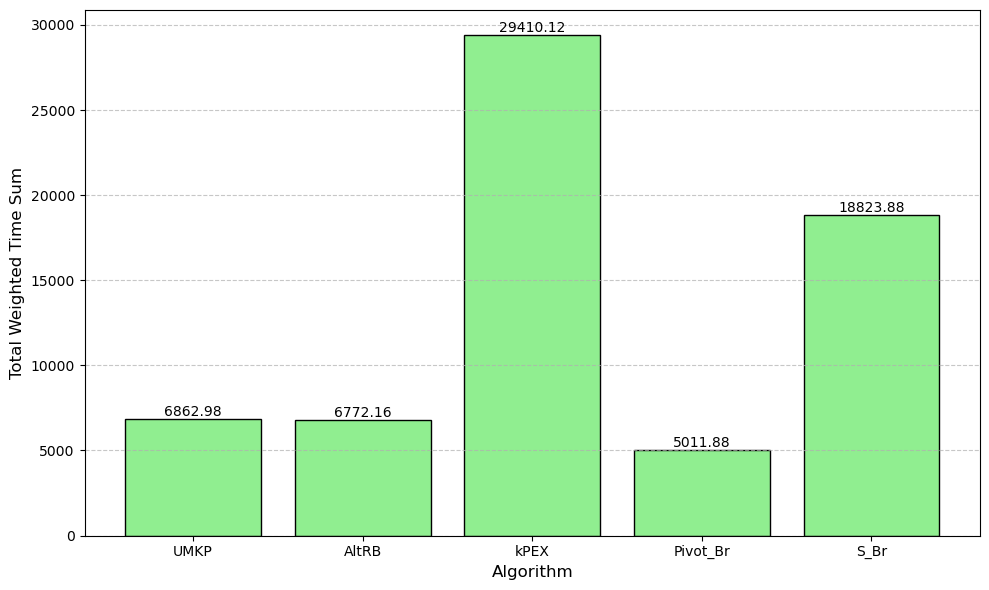

In [37]:
import pandas as pd

# Convert the dictionary to a DataFrame for plotting
df_overall = pd.DataFrame.from_dict(overall_fastest_weighted, orient='index', columns=['Weighted Sum'])
df_overall.index.name = 'Algorithm'

import matplotlib.pyplot as plt

# Create the plot
plt.figure(figsize=(10, 6))
bars = plt.bar(df_overall.index, df_overall['Weighted Sum'], color='lightgreen', edgecolor='black')

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, 
             f'{height:.2f}', ha='center', va='bottom')

# Customize the plot
plt.xlabel('Algorithm', fontsize=12)
plt.ylabel('Total Weighted Time Sum', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()